Error =  0° | Result = {'1': 1000} | Reliability = 100.00%
Error =  2° | Result = {'1': 999, '0': 1} | Reliability = 99.90%
Error =  5° | Result = {'1': 999, '0': 1} | Reliability = 99.90%
Error = 10° | Result = {'1': 989, '0': 11} | Reliability = 98.90%
Error = 15° | Result = {'1': 985, '0': 15} | Reliability = 98.50%
Error = 20° | Result = {'1': 974, '0': 26} | Reliability = 97.40%


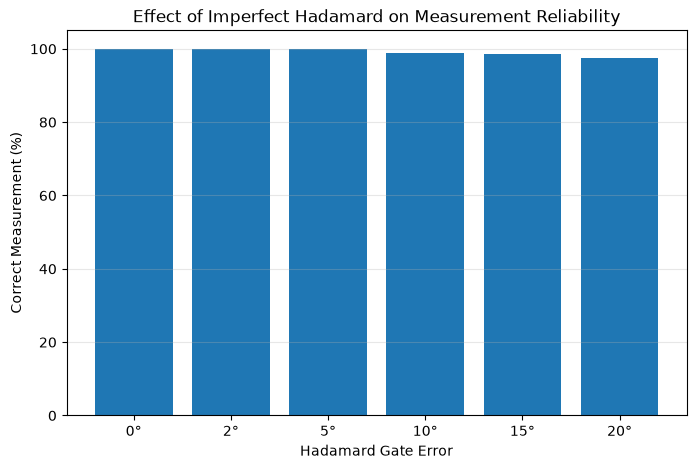

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
import numpy as np

simulator = AerSimulator()
errors = [0, 2, 5, 10, 15, 20]

reliability = []

for error in errors:

    qc = QuantumCircuit(2, 1)
    qc.h(0)
    qc.x(1)
    qc.h(1)
    qc.cx(0, 1)
    qc.h(0)
    qc.ry(np.radians(error), 0)

    # Measure
    qc.measure(0, 0)
    result = simulator.run(qc, shots=1000).result()
    counts = result.get_counts()

    correct = counts.get("1", 0)
    accuracy = (correct / 1000) * 100
    reliability.append(accuracy)

    print(
        f"Error = {error:2d}° | "
        f"Result = {counts} | "
        f"Reliability = {accuracy:.2f}%"
    )

plt.figure(figsize=(8, 5))

plt.bar(
    [str(x) + "°" for x in errors],
    reliability
)

plt.xlabel("Hadamard Gate Error")
plt.ylabel("Correct Measurement (%)")
plt.title("Effect of Imperfect Hadamard on Measurement Reliability")

plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.show()